# EDA 09 — HMEQ: giá trị thiếu và rò rỉ thông tin

Notebook này phân tích riêng **mẫu giá trị thiếu** của HMEQ. Kiểm tra rò rỉ (`reports/models/validity/`) cho thấy
một mô hình chỉ biết *cột nào bị thiếu* (không thấy giá trị nào) đạt AUC 0,836 — cao hơn Logistic Regression dùng
toàn bộ dữ liệu (0,803). Câu hỏi: đây là thông tin hợp lệ về người vay, hay dấu vết của quy trình ghi nhận hồ sơ sau
khi biết kết cục (rò rỉ)? Và cách ngăn rò rỉ ảnh hưởng thế nào đến kết quả.

Theo mô tả gốc, dữ liệu gồm *"recent applicants granted credit"*: các khoản vay đã được cấp, nhãn `BAD` được ghi
nhận sau đó (vỡ nợ hoặc quá hạn nghiêm trọng).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

from sklearn.model_selection import StratifiedKFold, cross_val_score
from lightgbm import LGBMClassifier
import seaborn as sns
NAME = "hmeq_missing"
df = pd.read_csv(INTERIM / "hmeq.csv")
X = df.drop(columns="target")
M = X.isna()
print(df.shape, f"bad rate {df.target.mean():.2%}")

(5960, 13) bad rate 19.95%


## 1. Mức thiếu và tỷ lệ xấu theo từng cột

,missing_pct,bad_if_missing_pct,bad_if_present_pct
DEBTINC,21.3,62.0,8.6
DEROG,11.9,12.3,21.0
DELINQ,9.7,12.4,20.8
MORTDUE,8.7,20.5,19.9
YOJ,8.6,12.6,20.6
NINQ,8.6,14.7,20.4
CLAGE,5.2,25.3,19.7
JOB,4.7,8.2,20.5
REASON,4.2,19.0,20.0
CLNO,3.7,23.9,19.8


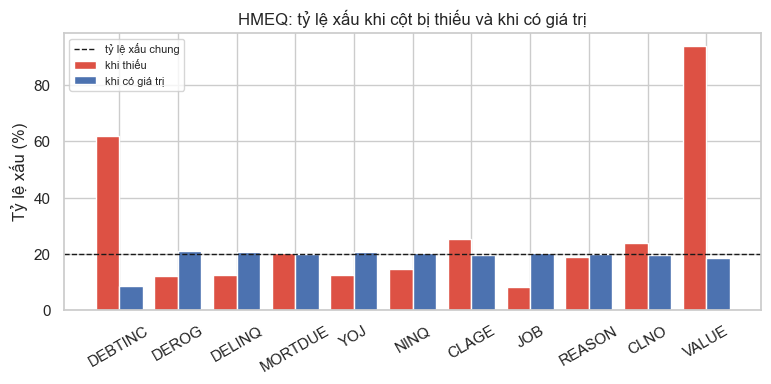

In [2]:
t = pd.DataFrame({
    "missing_pct": 100 * M.mean(),
    "bad_if_missing_pct": [100 * df.target[M[c]].mean() if M[c].any() else np.nan for c in X],
    "bad_if_present_pct": [100 * df.target[~M[c]].mean() for c in X],
}).round(1).sort_values("missing_pct", ascending=False)
display(t)
fig, ax = plt.subplots(figsize=(9, 3.6))
tt = t[t.missing_pct > 0]
x = np.arange(len(tt))
ax.bar(x - 0.2, tt.bad_if_missing_pct, 0.4, label="khi thiếu", color="#DD5144")
ax.bar(x + 0.2, tt.bad_if_present_pct, 0.4, label="khi có giá trị", color="#4C72B0")
ax.axhline(100 * df.target.mean(), color="k", ls="--", lw=1, label="tỷ lệ xấu chung")
ax.set_xticks(x, tt.index, rotation=30)
ax.set_ylabel("Tỷ lệ xấu (%)")
ax.set_title("HMEQ: tỷ lệ xấu khi cột bị thiếu và khi có giá trị")
ax.legend(fontsize=8)
eda.savefig(fig, "hmeq_missing_bad_rate")
plt.show()

## 2. Tỷ lệ xấu theo số cột bị thiếu và theo mẫu thiếu

In [3]:
n_miss = M.sum(axis=1)
display(df.groupby(n_miss.clip(upper=6))["target"].agg(n="size", bad_rate="mean").round(3)
        .rename_axis("số cột thiếu (≥6 gộp)").T)
pattern = M.apply(lambda r: " + ".join(c for c, v in r.items() if v) or "(đủ dữ liệu)", axis=1)
pat = df.groupby(pattern)["target"].agg(n="size", bad_rate="mean").sort_values("n", ascending=False)
display(pat.head(15).round(3))
big = pat[pat.n >= 30]
print(f"Các mẫu thiếu có ≥ 30 dòng: {len(big)}; tỷ lệ xấu từ {big.bad_rate.min():.1%} đến {big.bad_rate.max():.1%}")

số cột thiếu (≥6 gộp),0,1,2,3,4,5,6
n,3364.000,1589.000,449.000,219.000,64.000,83.000,192.00
bad_rate,0.089,0.381,0.401,0.178,0.094,0.096,0.26


,n,bad_rate
(đủ dữ liệu),3364,0.089
DEBTINC,883,0.612
YOJ,184,0.049
MORTDUE,166,0.084
DEROG,125,0.040
DEROG + DELINQ,91,0.011
DEROG + DELINQ + NINQ,87,0.000
JOB,81,0.012
REASON,70,0.114
MORTDUE + DEBTINC,52,0.654


Các mẫu thiếu có ≥ 30 dòng: 17; tỷ lệ xấu từ 0.0% đến 100.0%


**Đọc kết quả.** Việc thiếu dữ liệu tách nhãn theo **cả hai chiều**:

- thiếu `DEBTINC` (tỷ lệ nợ/thu nhập) → khoảng 61% xấu; thiếu cả `VALUE` và `DEBTINC` → 100% xấu;
- thiếu các biến lịch sử tín dụng (`DEROG`, `DELINQ`, `NINQ`) hoặc `JOB` → gần như 0–5% xấu;
- hồ sơ đầy đủ → khoảng 9% xấu.

Một quy luật "sạch" như vậy (100% so với 0%) khó giải thích bằng hành vi của người vay tại thời điểm nộp đơn; nó
phù hợp hơn với giả thuyết các trường được **điền hoặc để trống khác nhau tùy theo kết cục** (ví dụ hồ sơ khoản vay
xấu được xử lý, cập nhật khác hồ sơ khoản vay tốt).

## 3. Mẫu thiếu có cấu trúc: tương quan giữa các cờ thiếu

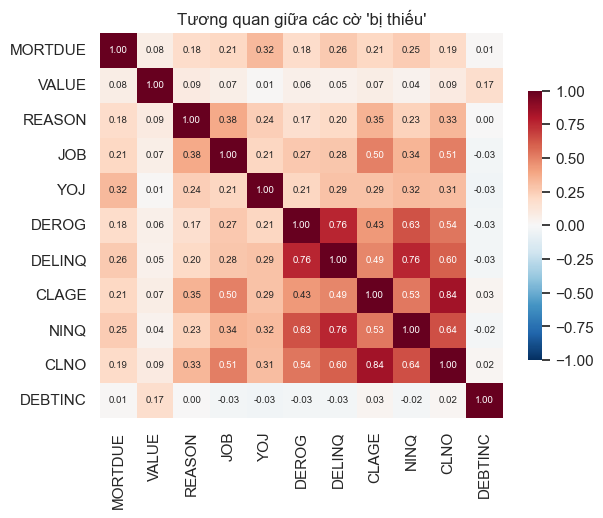

In [4]:
mc = M.loc[:, M.any()].astype(int)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(mc.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
ax.set_title("Tương quan giữa các cờ 'bị thiếu'")
eda.savefig(fig, "hmeq_missing_corr")
plt.show()

## 4. Chỉ riêng mẫu thiếu dự đoán được nhãn đến đâu?

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
ind = mc.astype(int)
auc_missing = cross_val_score(LGBMClassifier(n_estimators=100, verbose=-1), ind, df.target, cv=cv, scoring="roc_auc")
print(f"AUC 5-fold khi CHỈ dùng cờ thiếu (không dùng giá trị nào): {auc_missing.mean():.3f} ± {auc_missing.std():.3f}")
comp = df[~M.any(axis=1)]
print(f"Hồ sơ đầy đủ: {len(comp):,} dòng ({len(comp)/len(df):.1%}), tỷ lệ xấu {comp.target.mean():.1%}; "
      f"hồ sơ thiếu ít nhất một cột: {(M.any(axis=1)).sum():,} dòng, tỷ lệ xấu {df.target[M.any(axis=1)].mean():.1%}")

AUC 5-fold khi CHỈ dùng cờ thiếu (không dùng giá trị nào): 0.825 ± 0.011
Hồ sơ đầy đủ: 3,364 dòng (56.4%), tỷ lệ xấu 8.9%; hồ sơ thiếu ít nhất một cột: 2,596 dòng, tỷ lệ xấu 34.2%


## 5. Ngăn rò rỉ: hai phiên bản HMEQ

| Phiên bản | Cách làm | Ưu điểm | Nhược điểm |
|---|---|---|---|
| `hmeq` (gốc) | Tiền xử lý Baesens: median + nhóm `__missing__` | Đúng giao thức | Mô hình đọc được mẫu thiếu: nhóm `__missing__`, và cây nhận ra giá trị median được điền |
| `hmeq_complete` | Tầng A chỉ giữ hồ sơ đầy đủ (3.364 dòng) | Không còn giá trị thiếu nào | Đổi tổng thể: tỷ lệ xấu còn 8,9%; bỏ 44% dữ liệu |
| `hmeq_blind` | Giữ mọi dòng và đúng các fold; tầng B.1 điền mỗi giá trị thiếu bằng **một giá trị rút ngẫu nhiên** từ các giá trị quan sát được của cột đó trên train | Giữ tổng thể và đúng các fold; xóa nhóm `__missing__` và điểm median | Không xóa hết dấu vết: giá trị rút ngẫu nhiên phá vỡ quan hệ giữa các cột (ví dụ dư nợ và giá trị nhà), nên dòng từng thiếu vẫn nhận ra được một phần |

In [6]:
from src.models.compare_models import NAMES, RUNS
rows = []
for r in RUNS:
    s = pd.read_csv(ROOT / "reports" / "models" / r / "summary.csv").set_index("dataset")
    rows.append({"model": NAMES[r], **{v: s.loc[v, "auc"] for v in ["hmeq", "hmeq_blind", "hmeq_complete"]}})
res = pd.DataFrame(rows).set_index("model")
res["blind − gốc"] = res.hmeq_blind - res.hmeq
res["complete − gốc"] = res.hmeq_complete - res.hmeq
display(res.round(4))
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(res)); w = 0.27
for i, (c, lab, col) in enumerate([("hmeq", "gốc", "#999999"), ("hmeq_blind", "che giá trị thiếu", "#4C72B0"),
                                    ("hmeq_complete", "chỉ hồ sơ đầy đủ", "#55A868")]):
    ax.bar(x + (i - 1) * w, res[c], w, label=lab, color=col)
ax.set_xticks(x, res.index); ax.set_ylim(0.6, 1.0); ax.set_ylabel("AUC test")
ax.set_title("HMEQ: AUC trước và sau khi ngăn rò rỉ qua giá trị thiếu"); ax.legend(fontsize=8)
eda.savefig(fig, "hmeq_leakage_control_auc")
plt.show()

,hmeq,hmeq_blind,hmeq_complete,blind − gốc,complete − gốc
model,,,,,
LR,0.8030,0.7868,0.7864,-0.0163,-0.0167
KNN,0.8993,0.8598,0.7883,-0.0394,-0.1110
RF,0.9703,0.9436,0.9481,-0.0267,-0.0222
NB,0.7704,0.7716,0.8010,0.0012,0.0305
XGB,0.9615,0.9214,0.9213,-0.0402,-0.0402
LGBM,0.9573,0.9214,0.9177,-0.0359,-0.0396
CatBoost,0.9602,0.9196,0.9203,-0.0406,-0.0400


In [7]:
v = ROOT / "reports" / "models" / "validity" / "leakage.csv"
if v.exists():
    lk = pd.read_csv(v).set_index("dataset").loc[["hmeq", "hmeq_blind", "hmeq_complete"],
                                                ["missingness_only_auc", "missing_rows_detectable_auc"]]
    display(lk.round(3))
    print("missing_rows_detectable_auc: một mô hình có nhận ra được 'dòng này từng bị thiếu' từ ma trận sau tiền xử lý không "
          "(0,5 = không nhận ra).")

,missingness_only_auc,missing_rows_detectable_auc
dataset,,
hmeq,0.836,0.995
hmeq_blind,0.836,0.907
hmeq_complete,NaN,NaN


missing_rows_detectable_auc: một mô hình có nhận ra được 'dòng này từng bị thiếu' từ ma trận sau tiền xử lý không (0,5 = không nhận ra).


## 6. Kết luận

- Mẫu giá trị thiếu của HMEQ dự đoán nhãn mạnh hơn cả Logistic Regression dùng toàn bộ dữ liệu, và tách nhãn theo
  cả hai chiều (tới 100% xấu và 0% xấu). Đây nhiều khả năng là **rò rỉ do quy trình ghi nhận hồ sơ**, không phải thông
  tin có sẵn khi xét duyệt.
- Với tiền xử lý Baesens, mô hình nhận ra gần như chắc chắn dòng nào từng bị thiếu (AUC 0,995) qua nhóm `__missing__`
  và giá trị median được điền. `hmeq_blind` giảm khả năng này xuống 0,907 — chưa xóa hết, vì giá trị rút ngẫu nhiên
  không khớp với các cột còn lại. `hmeq_complete` loại bỏ hoàn toàn (không còn giá trị thiếu) nhưng đổi tổng thể.
- Dấu vết còn lại của `hmeq_blind` gần như không mang thông tin về nhãn: AUC của `hmeq_blind` và `hmeq_complete`
  (sạch tuyệt đối) gần như trùng nhau ở mọi mô hình cây và LR (chênh ≤ 0,005).
- Sau khi ngăn rò rỉ, AUC của mọi mô hình giảm (mô hình cây giảm khoảng 0,03–0,04), nhưng **thứ tự các mô hình gần như
  giữ nguyên** và mô hình cây vẫn hơn LR rất xa: lợi thế của mô hình cây trên HMEQ là thật, chỉ có mức AUC tuyệt đối
  bị thổi phồng bởi rò rỉ.